# Konveyör Bant Ürün Tespiti — YOLOv8s Final Model Eğitimi (27 Epoch, Roboflow v14)

Bu notebook, bitirme projesi final raporunda anlatılan modeli (**27Epoch.pt**) yeniden üretir.

| Ayar | Değer |
|---|---|
| Başlangıç modeli | `yolov8s.pt` (COCO ön-eğitimli) |
| Veri seti | Roboflow `cagla-bhxzs / graduationproject-iy9cg` **v14** (3342 train / 318 valid / 161 test) |
| Sınıflar | bowl, cream, cup, jar, lipstick, soap dispenser |
| Epoch | 27 |
| Görüntü boyutu | 800 |

**Çalıştırmadan önce:**
1. `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU` seç.
2. Sol menüdeki 🔑 **Secrets** bölümüne `ROBOFLOW_API_KEY` adıyla Roboflow API anahtarını ekle ve "Notebook access" anahtarını aç.
3. `Çalışma zamanı → Tümünü çalıştır`. Drive izni sorulunca onay ver.

Eğitim T4 GPU'da yaklaşık 30-45 dakika sürer. Sonunda model **Google Drive → `Bitirme_Model/27Epoch.pt`** olarak kaydedilir.

## 1. GPU kontrolü

In [ ]:
!nvidia-smi

Sat Oct 24 13:47:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Kurulum

In [ ]:
!pip install -q ultralytics roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


## 3. Google Drive bağlantısı (model kaybolmasın diye)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR = '/content/drive/MyDrive/Bitirme_Model'
os.makedirs(DRIVE_DIR, exist_ok=True)
print('Çıktılar buraya kaydedilecek:', DRIVE_DIR)

Mounted at /content/drive
Çıktılar buraya kaydedilecek: /content/drive/MyDrive/Bitirme_Model


## 4. Veri setini Roboflow'dan indir (v14)
API anahtarı koda yazılmaz, Colab Secrets'tan okunur.

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
project = rf.workspace("cagla-bhxzs").project("graduationproject-iy9cg")
dataset = project.version(14).download("yolov8", location="/content/datasets/GraduationProject-14")

import yaml
with open(f"{dataset.location}/data.yaml") as f:
    cfg = yaml.safe_load(f)
print("Sınıflar:", cfg['names'])
for split in ['train', 'valid', 'test']:
    n = len(os.listdir(f"{dataset.location}/{split}/images"))
    print(f"{split}: {n} görüntü")   # beklenen: 3342 / 318 / 161

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/GraduationProject-14 in yolov8:: 100%|██████████| 7654/7654 [00:00<00:00, 7800.33it/s]

Sınıflar: ['bowl', 'cream', 'cup', 'jar', 'lipstick', 'soap dispenser']
train: 3342 görüntü
valid: 318 görüntü
test: 161 görüntü


## 5. Eğitim — yolov8s, 27 epoch, imgsz=800

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=27,
    imgsz=800,
    plots=True,
    seed=0,
    project="/content/runs/detect",
    name="final27",
    exist_ok=True,
)
RUN_DIR = "/content/runs/detect/final27"

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/GraduationProject-14/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=27, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final27, nbs=64, nms=None, opset=None, opt

## 6. Modeli hemen Drive'a kaydet

In [ ]:
import shutil
best = f"{RUN_DIR}/weights/best.pt"
shutil.copy(best, f"{DRIVE_DIR}/27Epoch.pt")
shutil.copytree(RUN_DIR, f"{DRIVE_DIR}/egitim_ciktilari_final27", dirs_exist_ok=True)
print("Kaydedildi:", f"{DRIVE_DIR}/27Epoch.pt")

Kaydedildi: /content/drive/MyDrive/Bitirme_Model/27Epoch.pt


## 7. Doğrulama ve test seti değerlendirmesi
Rapordaki değerler (27. epoch, valid): **P=0.984, R=0.986, mAP50=0.991, mAP50-95=0.96**

In [ ]:
final = YOLO(f"{DRIVE_DIR}/27Epoch.pt")
for split in ["val", "test"]:
    m = final.val(data=f"{dataset.location}/data.yaml", split=split, imgsz=800, plots=False)
    print(f"\n[{split}] P={m.box.mp:.3f}  R={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1160.4±383.9 MB/s, size: 29.5 KB)
val: Scanning /content/datasets/GraduationProject-14/valid/labels.cache... 318 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 318/318 102.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 3.0it/s 6.7s
                   all        318        514      0.984       0.99      0.991      0.956
                  bowl         35         53      0.971          1      0.995      0.968
                 cream         25         41          1       0.97      0.993      0.946
                   cup        113        141          1      0.997      0.995      0.976
                   jar         21         33       0.96          1      0.992      0.975
              lipstick 

## 8. Grafikler

results.png


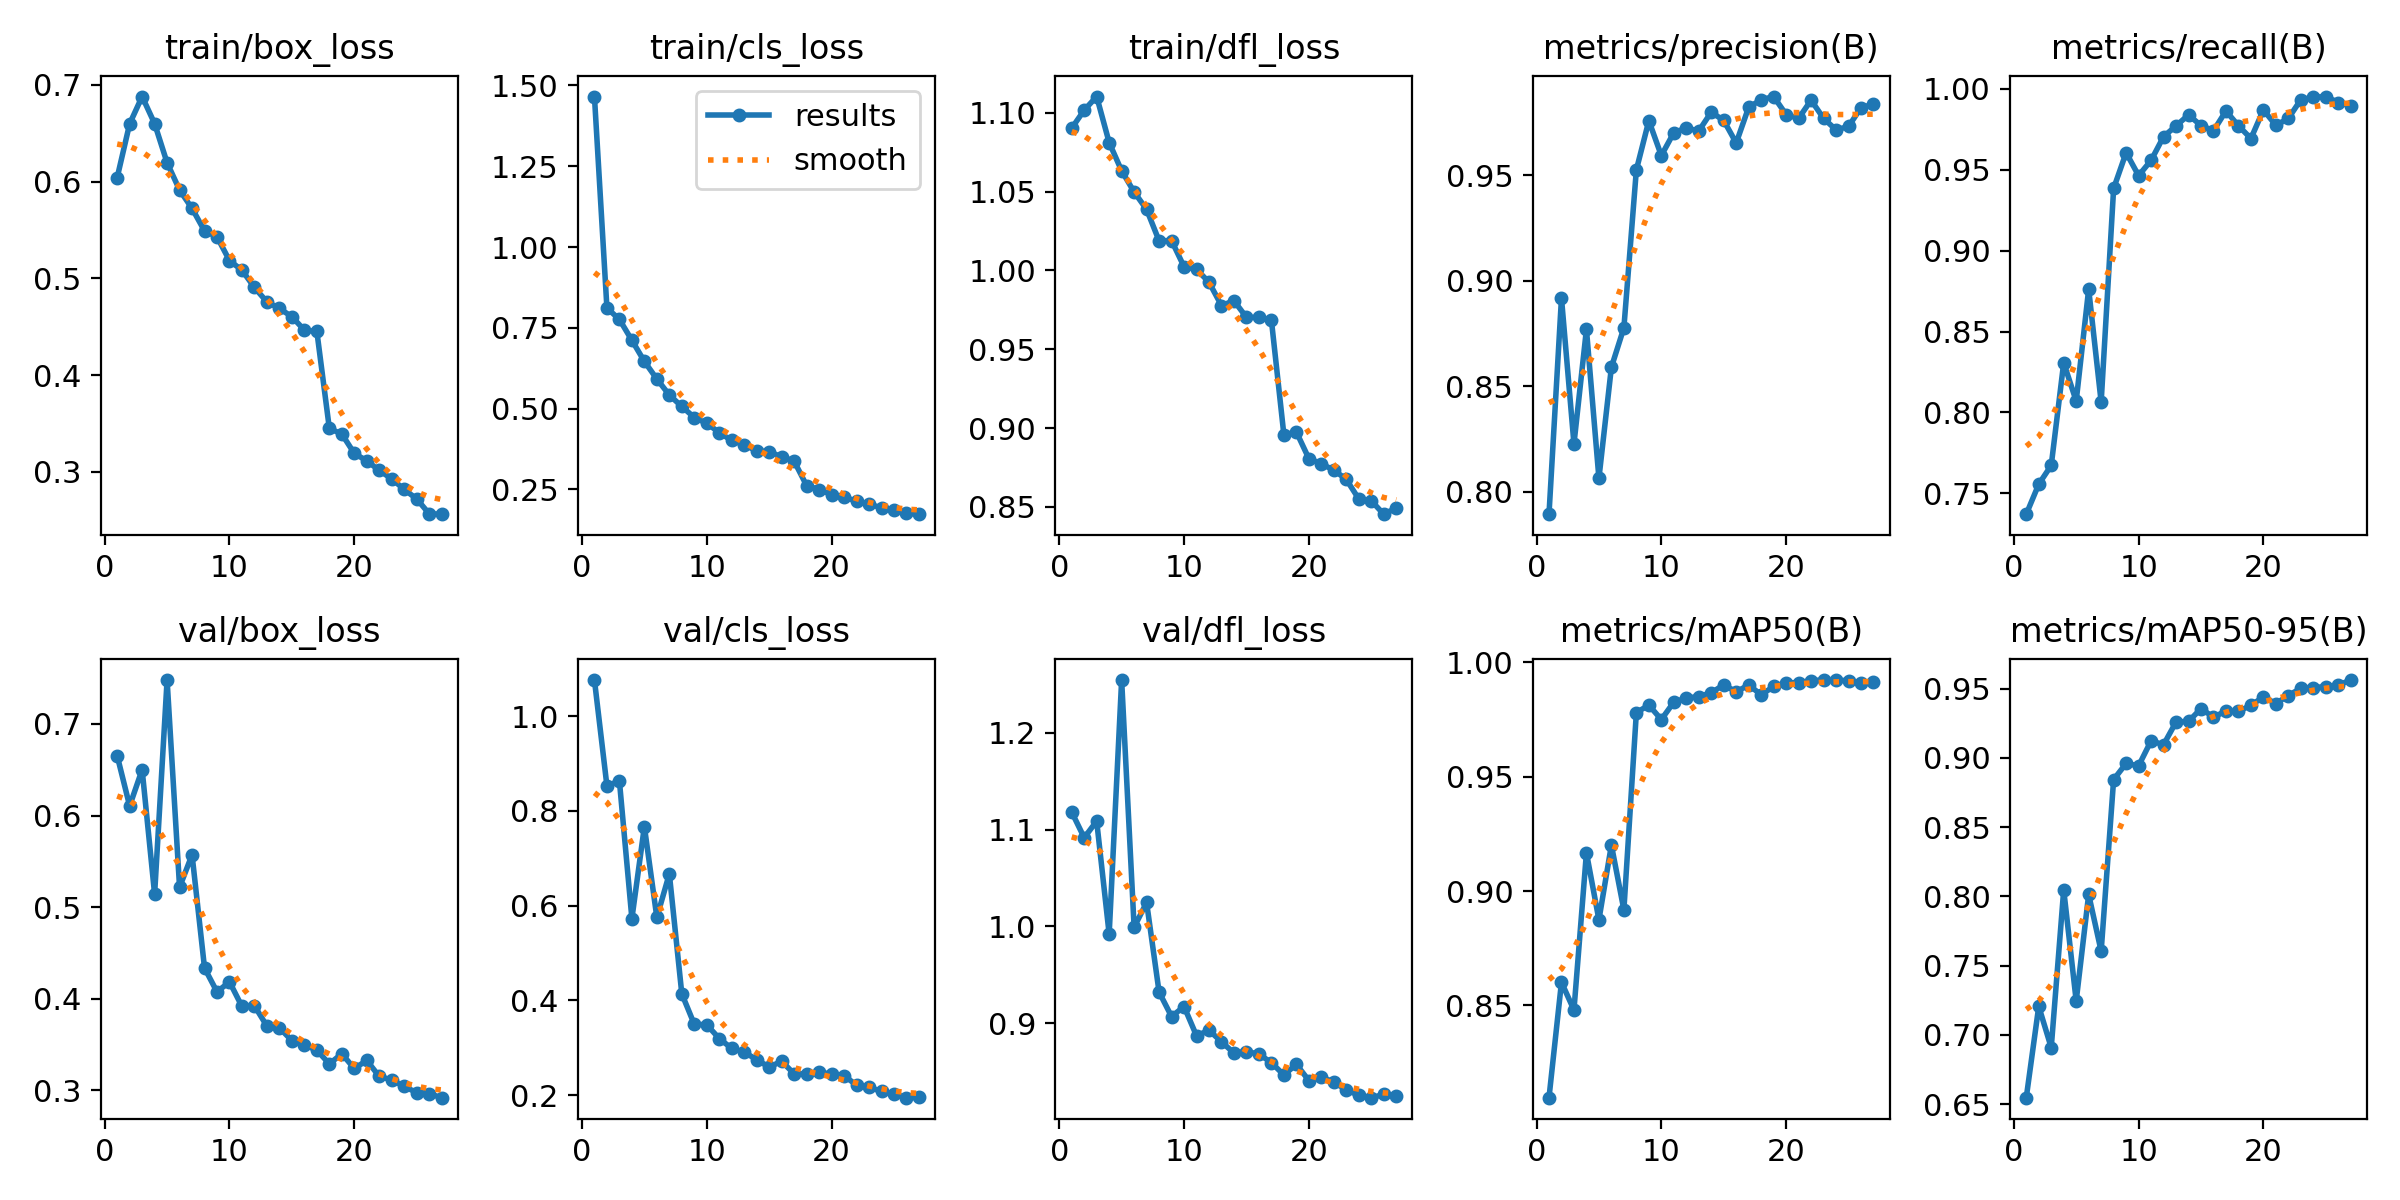

confusion_matrix.png


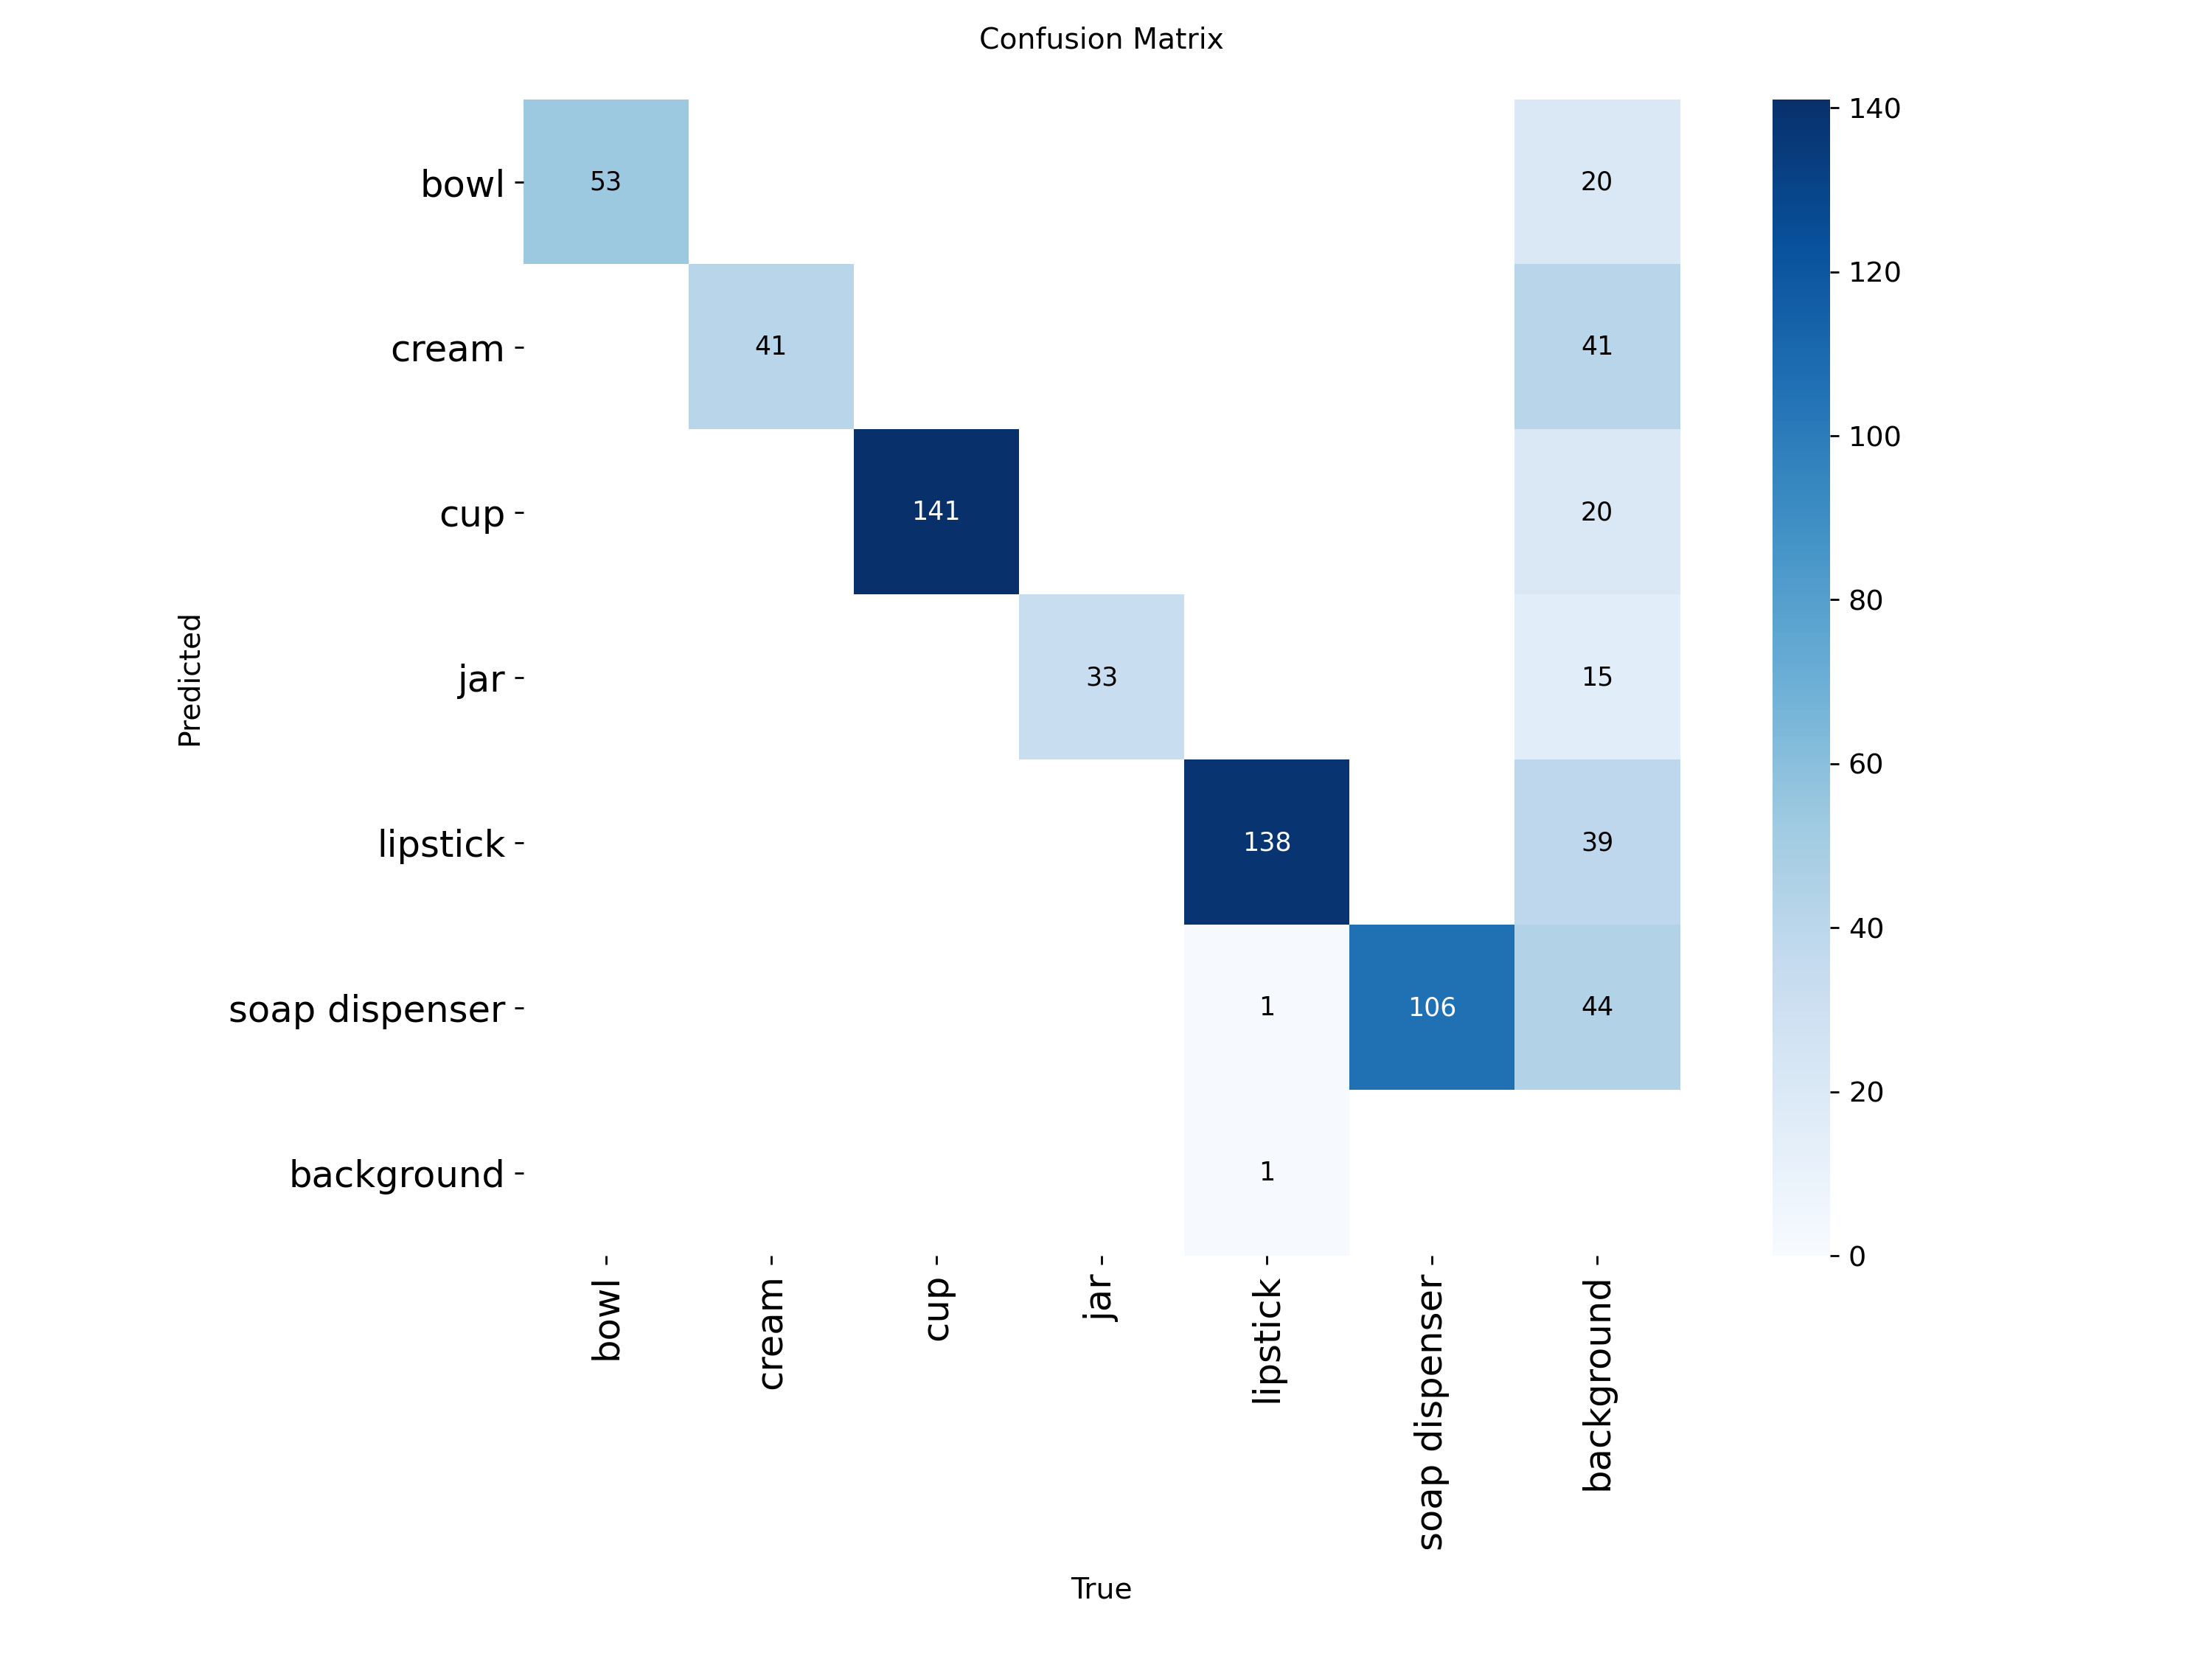

val_batch0_pred.jpg


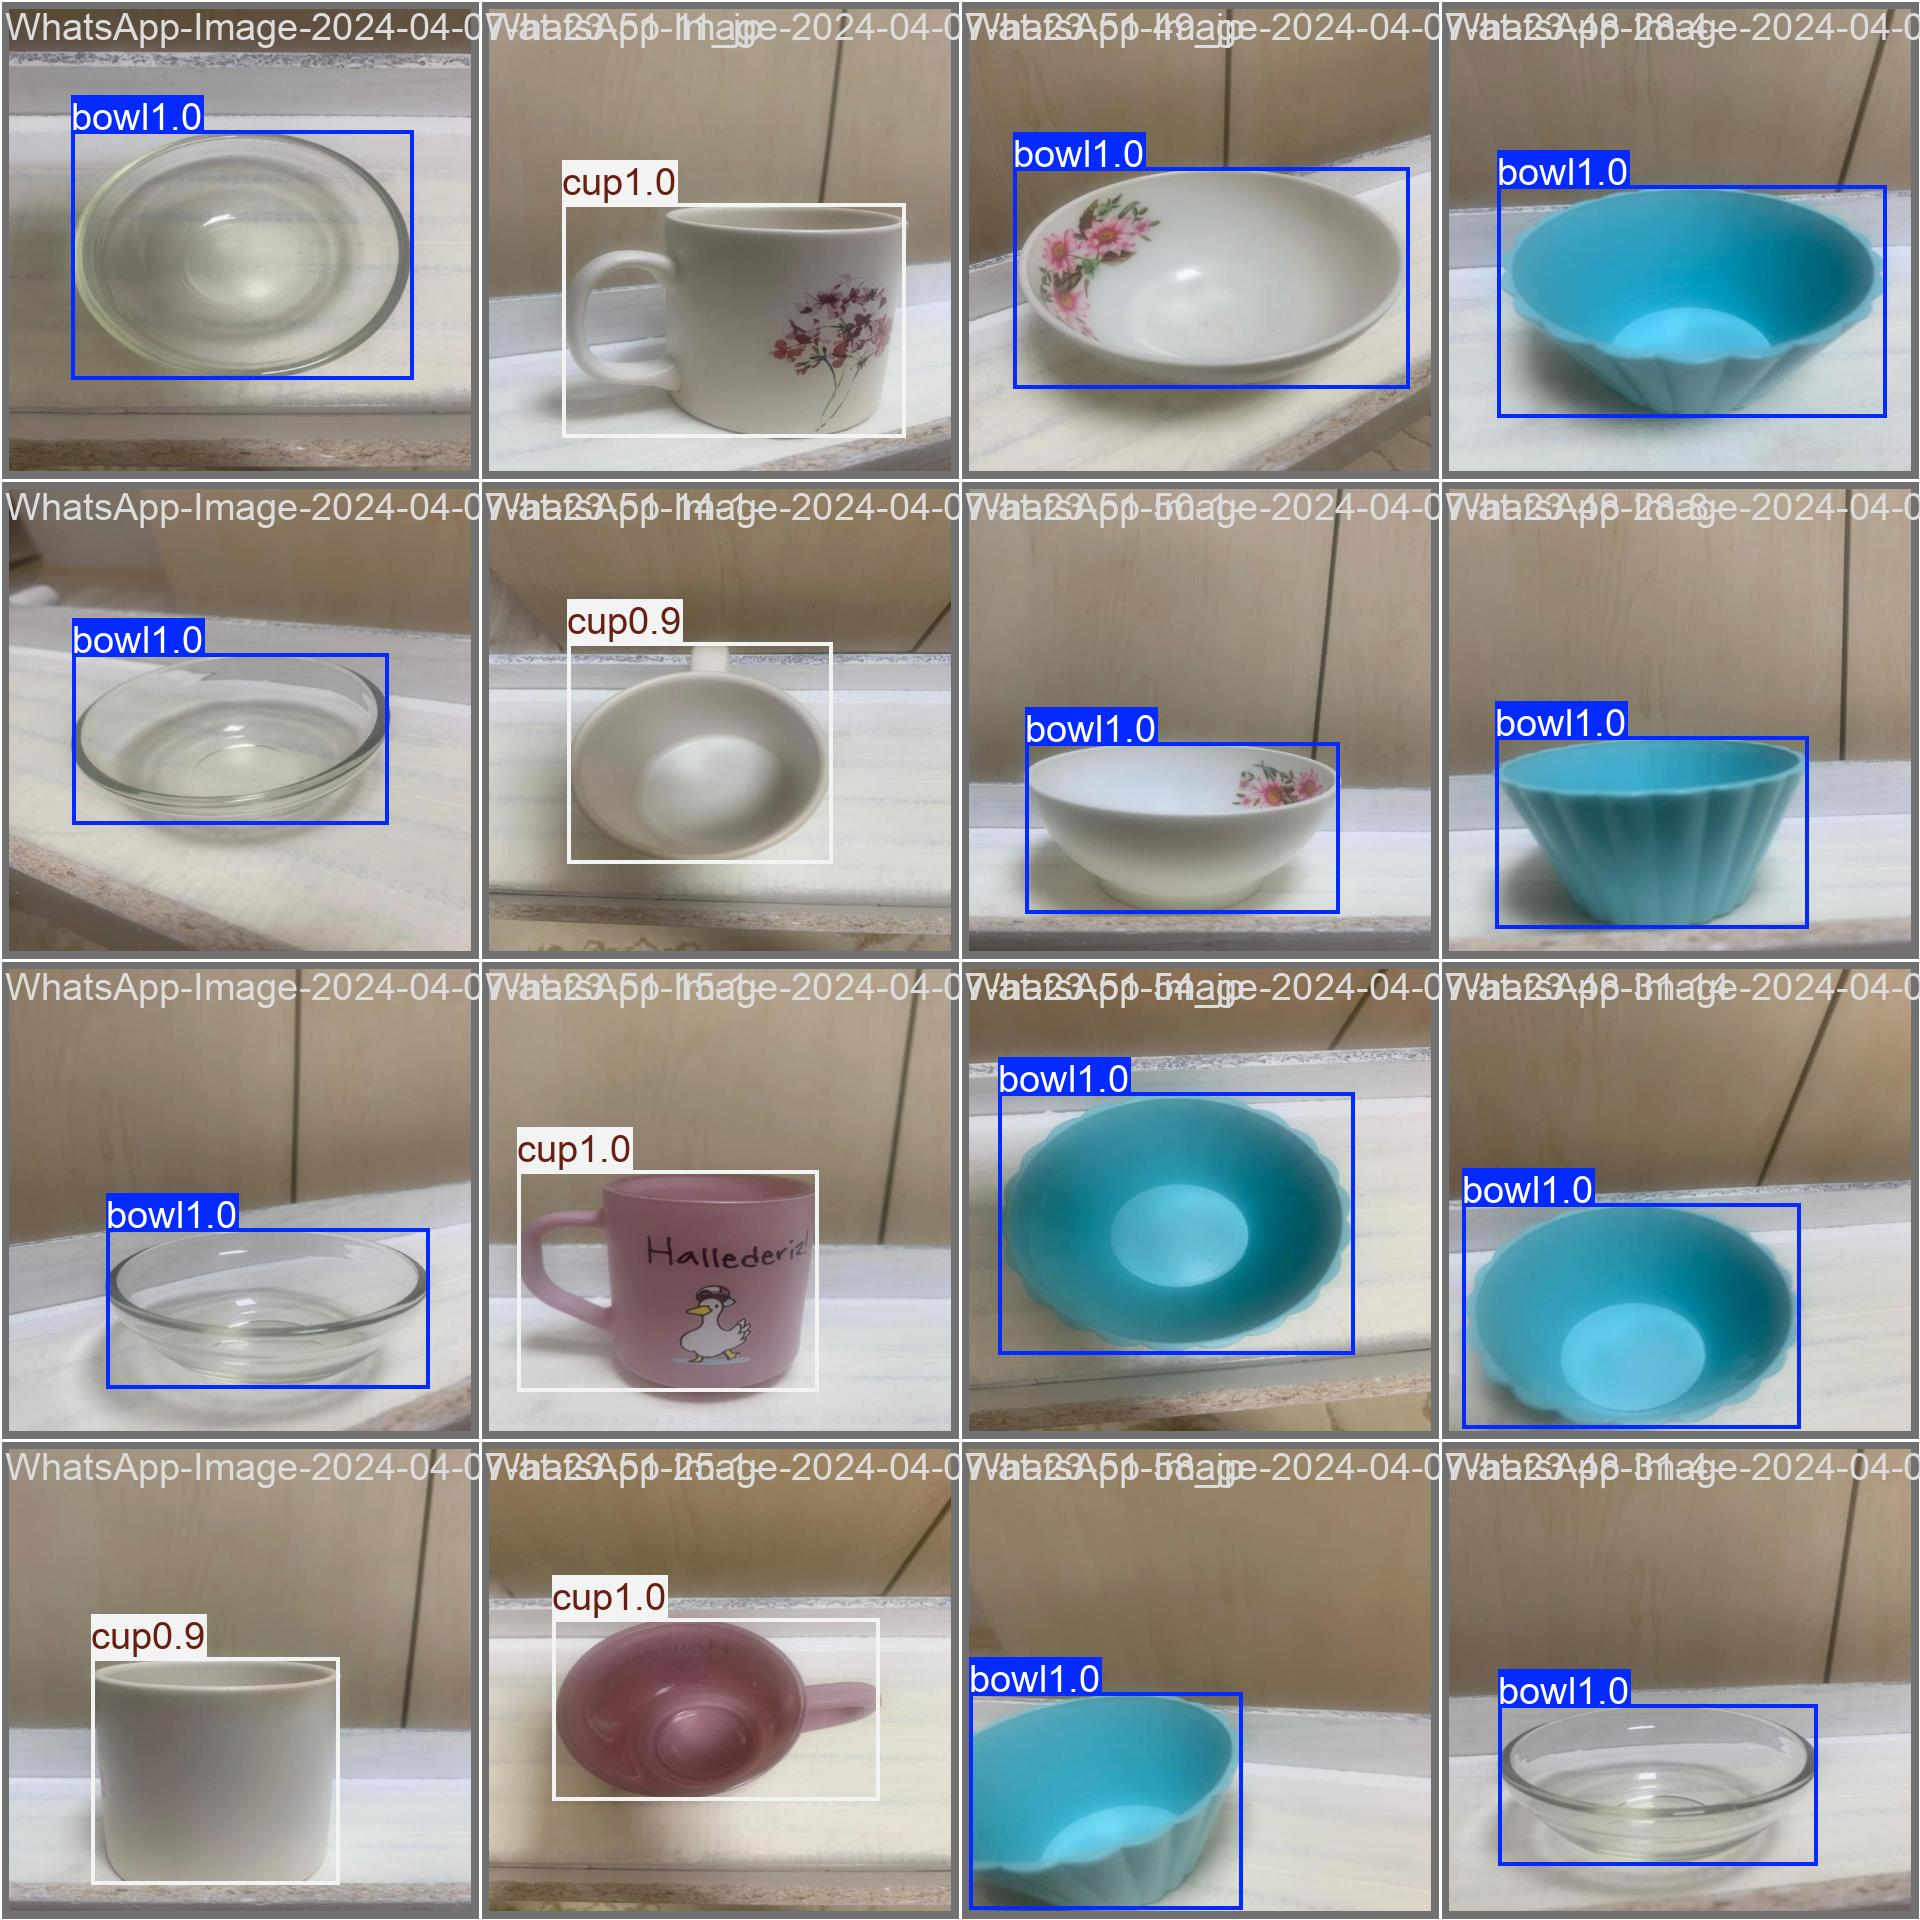

In [ ]:
from IPython.display import Image, display
for f in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
    p = f"{RUN_DIR}/{f}"
    if os.path.exists(p):
        print(f); display(Image(filename=p, width=700))

## 9. Test görüntüleri üzerinde tahmin

In [ ]:
final.predict(source=f"{dataset.location}/test/images", conf=0.25, save=True,
              project="/content/runs/detect", name="predict_test", exist_ok=True)
shutil.copytree("/content/runs/detect/predict_test", f"{DRIVE_DIR}/test_tahminleri", dirs_exist_ok=True)
print("Bitti ✅  Drive → Bitirme_Model klasörüne bak.")


image 1/161 /content/datasets/GraduationProject-14/test/images/IMG_2140_jpg.rf.b9dd88d8c2fabeff1b38d952849112b5.jpg: 800x800 1 soap dispenser, 20.4ms
image 2/161 /content/datasets/GraduationProject-14/test/images/IMG_2147_jpg.rf.e885c520a5e683a411e62a063b6d897f.jpg: 800x800 1 soap dispenser, 19.3ms
image 3/161 /content/datasets/GraduationProject-14/test/images/IMG_2159_jpg.rf.460702ab4227eb182e3513236e142dd6.jpg: 800x800 3 soap dispensers, 21.1ms
image 4/161 /content/datasets/GraduationProject-14/test/images/IMG_2163_jpg.rf.7ae9d4e1492d21d698728eb6a2c0b121.jpg: 800x800 1 soap dispenser, 20.0ms
image 5/161 /content/datasets/GraduationProject-14/test/images/IMG_2165_jpg.rf.2c20d449e5c1aa1df8f486d85a0d89b1.jpg: 800x800 1 soap dispenser, 21.4ms
image 6/161 /content/datasets/GraduationProject-14/test/images/IMG_2193_jpg.rf.cebf81a146424851b31a9ffedee0f4f9.jpg: 800x800 1 soap dispenser, 20.3ms
image 7/161 /content/datasets/GraduationProject-14/test/images/IMG_2197_jpg.rf.b8d200f28ae2a6fe08a